# Scan pipeline: orbit video to posed cameras

What `scripts/09_scan_object.py` does before splat training: keyframes, COLMAP SfM, and the object frame.

- **Modules:** `hurobo.scan` (`KeyframeSampler`, `SfmReconstructor`, `object_frame_from_orbit`), `hurobo.splat` (`render_splat_orbit`), `hurobo.utils.viewer`
- **Data:** the committed-by-script outputs of the dummy fruit-bowl clip under `data/scans/dummy_fruit_bowl/`

This notebook only *reads* the finished reconstruction (fast). To redo it:
`uv run python scripts/09_scan_object.py data/raw/dummy_orbits/<clip>.mp4 --name dummy_fruit_bowl`

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

In [2]:
import numpy as np

from hurobo.scan import largest_model, load_sparse_models, object_frame_from_orbit, sfm_result_from_model
from hurobo.utils.plotting import plot_image_row
from hurobo.utils.viewer import sfm_figure

SCAN_DIR = ROOT / "data/scans/bowl"  # bowl | dummy_fruit_bowl
models = load_sparse_models(SCAN_DIR / "colmap/sparse")
model = largest_model(models)  # same choice SfmReconstructor makes
print(
    f"{len(models)} sub-model(s); largest: {model.num_reg_images()} images, "
    f"{model.num_points3D():,} points, "
    f"mean reprojection error {model.compute_mean_reprojection_error():.2f} px"
)
sfm = sfm_result_from_model(model)  # poses and points only; no pixels needed for this notebook

1 sub-model(s); largest: 7 images, 349 points, mean reprojection error 0.32 px


## Cameras and sparse points in the SfM frame
The SfM frame is arbitrary in position, orientation and scale. Red pyramids are the registered keyframes.

In [3]:
sfm_figure(
    sfm.points_world, sfm.colors, sfm.t_world_cam_list, title="SfM frame: sparse points + keyframe cameras"
).show()

## Object frame from the orbit
`object_frame_from_orbit` finds the orbit plane (camera centres) and makes its normal +z, with the base at z=0. Afterwards the object sits upright on the origin, which is what `SplatFit.MATCH_BODY_XY` assumes.

In [4]:
sfm_obj = sfm.in_frame(object_frame_from_orbit(sfm))

sfm_figure(
    sfm_obj.points_world,
    sfm_obj.colors,
    sfm_obj.t_world_cam_list,
    title="Object frame: z up the orbit axis, base at z=0",
).show()
z_obj = sfm_obj.points_world[:, 2]
print(
    f"object-frame z range of sparse points: {np.percentile(z_obj, 2):.3f} .. {np.percentile(z_obj, 98):.3f}"
)

object-frame z range of sparse points: -0.000 .. 4.878


## Photo vs splat
Held-out-style check written by the script: the real keyframe next to the trained splat rendered from the same pose.

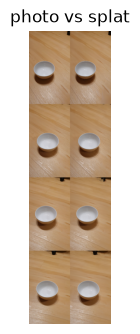

In [5]:
import matplotlib.pyplot as plt

plot_image_row({"photo vs splat": plt.imread(SCAN_DIR / "preview_photo_vs_splat.png")}, height_in=4)

## Rendered splat
The trained splat rasterised from cameras orbiting its centre (full Gaussians, not just centres), to inspect the 3D shape the scan produced. Drag the slider to orbit.

In [6]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.viewer import orbit_figure

SPLAT_PLY = ROOT / "data/splats" / f"{SCAN_DIR.name}.ply"
orbit_figure(render_splat_orbit(SPLAT_PLY), title=f"Rendered splat: {SCAN_DIR.name}").show()

## The best scans: bowl and plate
Chosen in `08_scan_parameter_sweep.ipynb` (Parts 2 and 3): the **bowl** from the high and low clips scanned together (`bowl_high_low/combined`, the only combination whose cameras agree) and the **plate** from the medium-height clip alone (`plate_med/robust_exhaustive`). The cameras and sparse points of each reconstruction, in the object frame:

In [7]:
from hurobo.best_scans import BestScans
from hurobo.scan_sweep import ScanSweep

best = BestScans()
for name, sweep_dir, config in [
    ("bowl: high + low", best.bowl_sfm_dir, "combined"),
    ("plate: medium", best.plate_sfm_dir, "robust_exhaustive"),
]:
    result = next(r for r in ScanSweep.load(sweep_dir) if r.config.name == config)
    sfm_best = result.load_sfm()
    sfm_best_obj = sfm_best.in_frame(object_frame_from_orbit(sfm_best))
    sfm_figure(
        sfm_best_obj.points_world,
        sfm_best_obj.colors,
        sfm_best_obj.t_world_cam_list,
        title=f"Best scan, {name}",
    ).show()

### The extracted objects
Each object alone (floor cut away, upright, base at z = 0). The plate is shown as scanned and with its gaps closed by the measured shape prior (D-009; the interior of the filled one is the prior, not the scan).

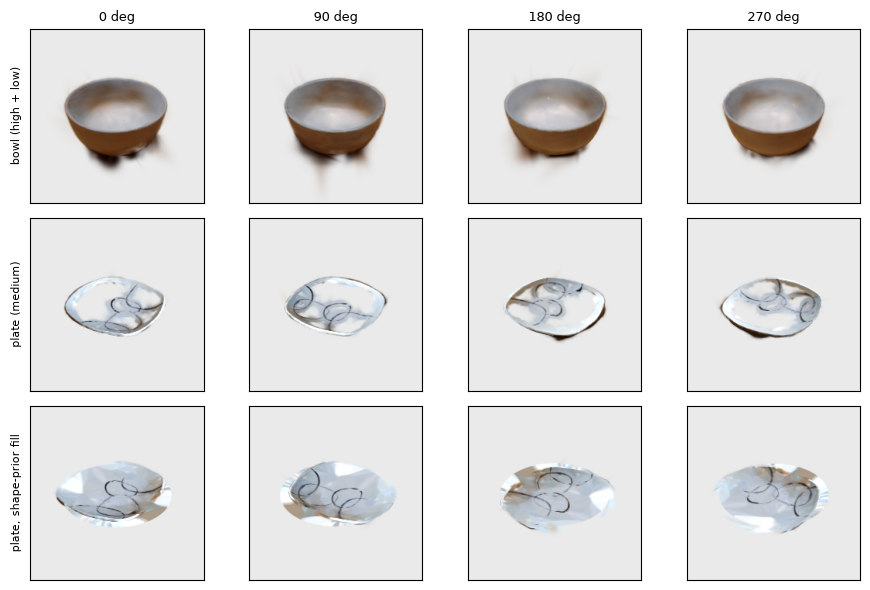

In [8]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.plotting import plot_image_grid

plot_image_grid(
    {
        label: render_splat_orbit(ply, num_views=4, image_size=224, elevation_deg=35)
        for label, ply in {
            "bowl (high + low)": best.bowl_ply,
            "plate (medium)": best.plate_ply,
            "plate, shape-prior fill": best.plate_filled_ply,
        }.items()
    },
    column_titles=["0 deg", "90 deg", "180 deg", "270 deg"],
)

### Against the measurements
These scans have no metric board, so their units are arbitrary and only the height / diameter ratio can be compared with `measurements.yaml`. (The bowl height there is still marked TODO.)

In [9]:
from hurobo.best_scans import scan_vs_measurement
from hurobo.real_setup import RealSetup

scan_vs_measurement(best, RealSetup.load()).set_index("object")

,scan diameter (units),scan height (units),scan height/diameter,real height/diameter,real diameter (cm),metres per scan unit
object,,,,,,
bowl,2.179,0.861,0.395,0.486,13.8,0.063
plate,2.464,0.209,0.085,0.110,25.5,0.104
plate (shape-prior fill),2.168,0.207,0.096,0.110,25.5,0.118
